In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
)
from sklearn.model_selection import train_test_split

In [10]:
# 1. Load Data
df = pd.read_csv("D:\Downloads\Churn_Modelling.csv")
df_clean = df.drop(columns=["RowNumber", "CustomerId", "Surname"])

In [11]:
# 2. Encode Categoricals
df_encoded = pd.get_dummies(df_clean, columns=["Geography", "Gender"], drop_first=True)

X = df_encoded.drop("Exited", axis=1)
y = df_encoded["Exited"]

In [12]:
# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [13]:
# 4. Model Training (Gradient Boosting - Non-RFC Algorithm)
model = HistGradientBoostingClassifier(random_state=42, class_weight="balanced")
model.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.1
,max_iter,100
,max_leaf_nodes,31
,max_depth,None
,min_samples_leaf,20
,l2_regularization,0.0
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'
,monotonic_cst,None


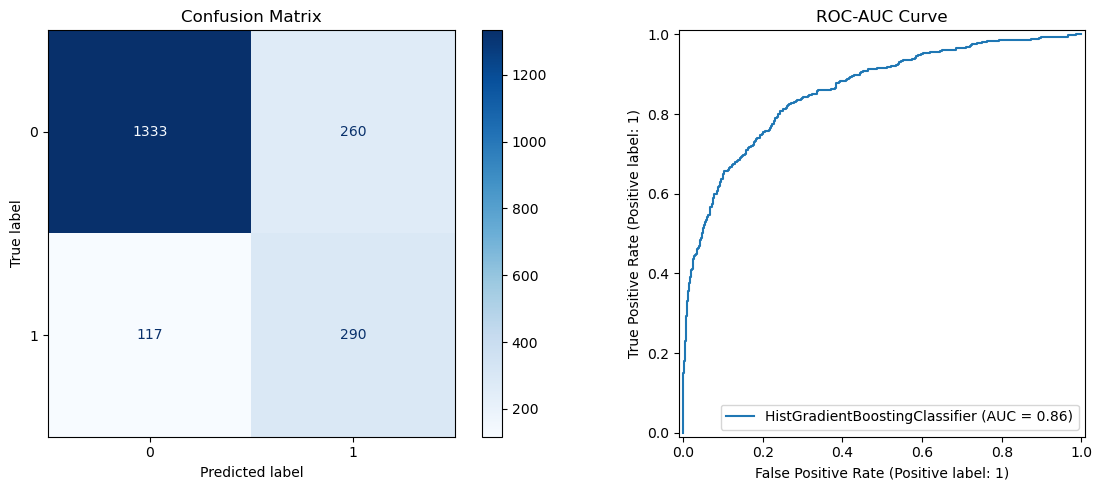

In [16]:
# 5. Generate Evaluation Charts for Assignment Report
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Plot 1: Confusion Matrix
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=axes[0], cmap="Blues")
axes[0].set_title("Confusion Matrix")
# Plot 2: ROC Curve
RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[1])
axes[1].set_title("ROC-AUC Curve")

plt.tight_layout()
plt.savefig("model_evaluation.png", dpi=300)
plt.show()

In [17]:
# 6. Performance Summary
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.84      0.88      1593
           1       0.53      0.71      0.61       407

    accuracy                           0.81      2000
   macro avg       0.72      0.77      0.74      2000
weighted avg       0.84      0.81      0.82      2000

